# XGBoost: прогноз потребления на сутки вперёд — все 5 областей
Настройки по умолчанию: `RETRAIN_EVERY = 14` для скорости, `QUICK = False` для полного года.

In [28]:
import os, time, warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    import xgboost as xgb
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "xgboost"], check=True)
    import xgboost as xgb
from xgboost import XGBRegressor

try:
    from IPython.display import display
except ImportError:
    display = print

plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
os.makedirs("figures", exist_ok=True)
os.makedirs("results", exist_ok=True)
print("XGBoost", xgb.__version__)

XGBoost 3.4.1


## 0. Настройки эксперимента

- `RETRAIN_EVERY = 14` — переобучение раз в две недели, быстро и почти без потери качества.
- `QUICK = True` — быстрая проверка на 2 месяцах и 100 деревьях.
- Для строгого протокола «каждые сутки» поставь `RETRAIN_EVERY = 1`, но это очень долго на 5 областях.

In [29]:
# ===================== НАСТРОЙКИ =====================
QUICK = False
TEST_START, TEST_END = "2025-01-01", "2025-12-31"
RETRAIN_EVERY = 1
N_ESTIMATORS = 300
# =====================================================
if QUICK:
    TEST_END, RETRAIN_EVERY, N_ESTIMATORS = "2025-02-28", 7, 100

XGB_PARAMS = dict(
    n_estimators=N_ESTIMATORS, learning_rate=0.05, max_depth=6, min_child_weight=5,
    subsample=0.8, colsample_bytree=0.8, reg_lambda=1.0,
    tree_method="hist", n_jobs=-1, random_state=0)

REGIONS = {"Киров": "33_kyrov.csv", "Курган": "37_kurgan.csv", "Тюмень": "71_tumen.csv",
           "Челябинск": "75_chelyabinsk.csv", "Удмуртия": "94_udmurtya.csv"}

HOLIDAYS = {(1, d) for d in range(1, 9)} | {(2, 23), (3, 8), (5, 1), (5, 9), (6, 12), (11, 4)}
print("тест:", TEST_START, "→", TEST_END, "| переобучение каждые", RETRAIN_EVERY, "сут. | деревьев:", N_ESTIMATORS)

тест: 2025-01-01 → 2025-12-31 | переобучение каждые 1 сут. | деревьев: 300


## 1. Данные и единая предобработка

Та же логика, что в `protocol_colab`: нули = пропуски, интерполяция по времени, метрики только по реально измеренным часам.

In [30]:
BASE_URL = "https://raw.githubusercontent.com/GeoPlayerRu/electroprognosis/main/data/raw/"
DATA_DIR = os.environ.get("DATA_DIR")

def read_raw(fname):
    src = os.path.join(DATA_DIR, fname) if DATA_DIR else BASE_URL + fname
    return pd.read_csv(src, parse_dates=["date"])

try:
    RAW = {n: read_raw(f) for n, f in REGIONS.items()}
except Exception as e:
    print("Не удалось скачать данные из GitHub:", e)
    print("Загрузи вручную файлы raw из репозитория")
    from google.colab import files
    up = files.upload()
    RAW = {n: pd.read_csv(k, parse_dates=["date"]) for n, k in zip(REGIONS, up.keys())}

def preprocess(raw):
    d = raw.drop(columns=["Unnamed: 0"], errors="ignore").drop_duplicates("date").set_index("date").sort_index()
    act = d["actual_consumption"].astype(float).mask(lambda s: s <= 0)
    plan = d["planned_consumption"].astype(float).mask(lambda s: s <= 0)
    idx = pd.date_range(d.index.min(), act.last_valid_index(), freq="h")
    act, plan = act.reindex(idx), plan.reindex(idx)
    obs = act.notna()
    act = act.interpolate(method="time")
    plan = plan.interpolate(method="time").bfill().ffill()
    return pd.DataFrame({"y": act, "plan": plan, "obs": obs})

PRE = {n: preprocess(r) for n, r in RAW.items()}
common_start = max(p.index[0] for p in PRE.values())
common_end = min(p.index[p.index.hour == 23].max() for p in PRE.values())
PRE = {n: p.loc[common_start:common_end] for n, p in PRE.items()}
Y = {n: p["y"] for n, p in PRE.items()}
PLAN = {n: p["plan"] for n, p in PRE.items()}
OBS = {n: p["obs"] for n, p in PRE.items()}

info = pd.DataFrame({n: {"часов": len(p), "восстановлено": int((~p.obs).sum()),
                         "доля восстановленных, %": round((~p.obs).mean()*100, 1)} for n, p in PRE.items()}).T
print(f"Общий период: {common_start:%d.%m.%Y} → {common_end:%d.%m.%Y %H:%M}")
display(info)

Общий период: 01.01.2022 → 22.09.2026 23:00


,часов,восстановлено,"доля восстановленных, %"
Киров,41424.0,1727.0,4.2
Курган,41424.0,1728.0,4.2
Тюмень,41424.0,1.0,0.0
Челябинск,41424.0,1729.0,4.2
Удмуртия,41424.0,1.0,0.0


## 2. Признаки

Все признаки известны в 00:00 суток прогноза. Модель предсказывает отношение нагрузки к недельному уровню, затем прогноз умножается на уровень обратно.

In [31]:
def build_features(y, plan):
    idx = y.index
    X = pd.DataFrame({
        "hour": idx.hour, "dow": idx.dayofweek,
        "is_weekend": (idx.dayofweek >= 5).astype(int),
        "is_holiday": [int((m, d) in HOLIDAYS) for m, d in zip(idx.month, idx.day)],
        "doy": idx.dayofyear}, index=idx)
    level = y.shift(24).rolling(168).mean()
    X["level"] = level
    X["lag24_rel"] = y.shift(24) / level
    X["lag48_rel"] = y.shift(48) / level
    X["lag168_rel"] = y.shift(168) / level
    X["mean24_rel"] = y.shift(24).rolling(24).mean() / level
    X["max24_rel"] = y.shift(24).rolling(24).max() / level
    X["plan_rel"] = plan / level
    return X

FE = {n: build_features(Y[n], PLAN[n]) for n in Y}
TARGET = {n: Y[n] / FE[n]["level"] for n in Y}
OWN = ["hour", "dow", "is_weekend", "is_holiday", "doy",
       "lag24_rel", "lag48_rel", "lag168_rel", "mean24_rel", "max24_rel"]
print("признаков без плана:", len(OWN), "| с планом:", len(OWN) + 1)

признаков без плана: 10 | с планом: 11


## 3. Скользящая оценка по 5 областям

Для каждого блока из `RETRAIN_EVERY` суток: обучаемся на всех данных до начала блока, предсказываем сутки блока, окно сдвигается. Отдельно для каждой области: с планом и без плана.

In [32]:
test_days = pd.date_range(TEST_START, TEST_END)
test_idx = pd.date_range(test_days[0], test_days[-1] + pd.Timedelta(hours=23), freq="h")
origins = list(pd.date_range(TEST_START, TEST_END, freq=f"{RETRAIN_EVERY}D"))
blocks = [(o, min(o + pd.Timedelta(days=RETRAIN_EVERY), test_days[-1] + pd.Timedelta(days=1))) for o in origins]
print(f"тестовых суток: {len(test_days)}, блоков на область: {len(blocks)}")

def rolling_forecast(name, use_plan):
    X = FE[name] if use_plan else FE[name].drop(columns=["plan_rel"])
    cols = OWN + (["plan_rel"] if use_plan else [])
    tgt, level = TARGET[name], X["level"]
    ok = X[cols].notna().all(axis=1) & tgt.notna()
    pred = pd.Series(np.nan, index=test_idx)
    model = None
    t0 = time.time()
    for o, e in blocks:
        tr = ok & (X.index < o)
        model = XGBRegressor(**XGB_PARAMS).fit(X.loc[tr, cols], tgt[tr])
        sel = (X.index >= o) & (X.index < e)
        pred.loc[X.index[sel]] = model.predict(X.loc[sel, cols]) * level[sel].values
    print(f"{name}: {'с планом' if use_plan else 'без плана'} готово за {time.time()-t0:.0f} с")
    return pred, model

V_PLAN, V_NOPLAN = "XGBoost + план", "XGBoost без плана"
B_PLAN, B_NAIVE = "Плановое потребление (портал)", "Как неделю назад"
ALL_VARIANTS = [V_PLAN, V_NOPLAN, B_PLAN, B_NAIVE]

SERIES_PRED = {n: {} for n in Y}
MODELS = {}
t0 = time.time()
for n in Y:
    SERIES_PRED[n][V_PLAN], MODELS[(n, V_PLAN)] = rolling_forecast(n, use_plan=True)
    SERIES_PRED[n][V_NOPLAN], _ = rolling_forecast(n, use_plan=False)
    print(f"{n}: готово ({time.time()-t0:.0f} с)")

to_mat = lambda s: s.loc[test_idx].values.reshape(-1, 24)
YT = {n: to_mat(Y[n]) for n in Y}
MT = {n: to_mat(OBS[n]).astype(bool) for n in Y}
PRED = {n: {v: to_mat(s) for v, s in SERIES_PRED[n].items()} for n in Y}
for n in Y:
    PRED[n][B_PLAN] = to_mat(PLAN[n])
    PRED[n][B_NAIVE] = to_mat(Y[n].shift(168))

тестовых суток: 365, блоков на область: 365
Киров: с планом готово за 475 с
Киров: без плана готово за 441 с
Киров: готово (916 с)
Курган: с планом готово за 475 с
Курган: без плана готово за 446 с
Курган: готово (1837 с)
Тюмень: с планом готово за 482 с
Тюмень: без плана готово за 432 с
Тюмень: готово (2750 с)
Челябинск: с планом готово за 481 с
Челябинск: без плана готово за 449 с
Челябинск: готово (3681 с)
Удмуртия: с планом готово за 475 с
Удмуртия: без плана готово за 442 с
Удмуртия: готово (4597 с)


## 4. Метрики: MAE, RMSE, R², MAPE, Top-1/3/5

Top-N Hit Rate — доля суток, где предсказанный максимум попал в N фактических пиковых часов. Для Top-1 это точное попадание в самый нагруженный час.

In [33]:
def topn_hits(Y_, P_, M_, n):
    ty = np.argsort(np.where(M_, Y_, -np.inf), axis=1)[:, -n:]
    tp = np.argsort(np.where(M_, P_, -np.inf), axis=1)[:, -n:]
    return np.array([len(set(a) & set(b)) / n for a, b in zip(ty, tp)])

def metrics(Y_, P_, M_):
    e, yv = (P_ - Y_)[M_], Y_[M_]
    h1 = topn_hits(Y_, P_, M_, 1)
    h3 = topn_hits(Y_, P_, M_, 3)
    h5 = topn_hits(Y_, P_, M_, 5)
    return {"MAE": np.abs(e).mean(), "RMSE": np.sqrt((e**2).mean()),
            "R2": 1 - (e**2).sum() / ((yv - yv.mean())**2).sum(),
            "MAPE": (np.abs(e) / yv).mean() * 100,
            "Top1": h1.mean(), "Top3": h3.mean(), "Top5": h5.mean(),
            "Top3_2plus": (np.round(h3*3) >= 2).mean()}

rows = [dict(region=n, variant=v, **metrics(YT[n], PRED[n][v], MT[n]))
        for n in Y for v in ALL_VARIANTS]
res = pd.DataFrame(rows)
avg = res.groupby("variant")[["MAE", "RMSE", "R2", "MAPE", "Top1", "Top3", "Top5", "Top3_2plus"]].mean().reindex(ALL_VARIANTS)
print("Среднее по 5 областям:")
display(avg.round(3))
print("\nTop-1 / Top-3 / Top-5 по областям:")
for col in ["Top1", "Top3", "Top5"]:
    print(f"\n{col}:")
    display(res.pivot(index="variant", columns="region", values=col).reindex(ALL_VARIANTS).round(3))

Среднее по 5 областям:


,MAE,RMSE,R2,MAPE,Top1,Top3,Top5,Top3_2plus
variant,,,,,,,,
XGBoost + план,31.518,40.084,0.974,1.716,0.264,0.515,0.628,0.513
XGBoost без плана,46.177,60.662,0.956,2.161,0.268,0.498,0.614,0.499
Плановое потребление (портал),31.839,40.494,0.973,1.762,0.260,0.497,0.611,0.493
Как неделю назад,84.107,110.157,0.870,3.608,0.223,0.448,0.569,0.419



Top-1 / Top-3 / Top-5 по областям:

Top1:


region,Киров,Курган,Тюмень,Удмуртия,Челябинск
variant,,,,,
XGBoost + план,0.285,0.211,0.373,0.301,0.151
XGBoost без плана,0.304,0.208,0.353,0.318,0.156
Плановое потребление (портал),0.274,0.200,0.381,0.301,0.145
Как неделю назад,0.258,0.173,0.337,0.227,0.121



Top3:


region,Киров,Курган,Тюмень,Удмуртия,Челябинск
variant,,,,,
XGBoost + план,0.593,0.429,0.631,0.556,0.368
XGBoost без плана,0.616,0.428,0.551,0.542,0.352
Плановое потребление (портал),0.543,0.416,0.619,0.538,0.366
Как неделю назад,0.551,0.369,0.521,0.479,0.318



Top5:


region,Киров,Курган,Тюмень,Удмуртия,Челябинск
variant,,,,,
XGBoost + план,0.684,0.580,0.688,0.662,0.525
XGBoost без плана,0.693,0.580,0.622,0.671,0.505
Плановое потребление (портал),0.659,0.564,0.690,0.631,0.513
Как неделю назад,0.659,0.513,0.599,0.608,0.467


## 5. Графики

MAPE по месяцам, факт против прогноза для одной области, совпадение пиковых часов.

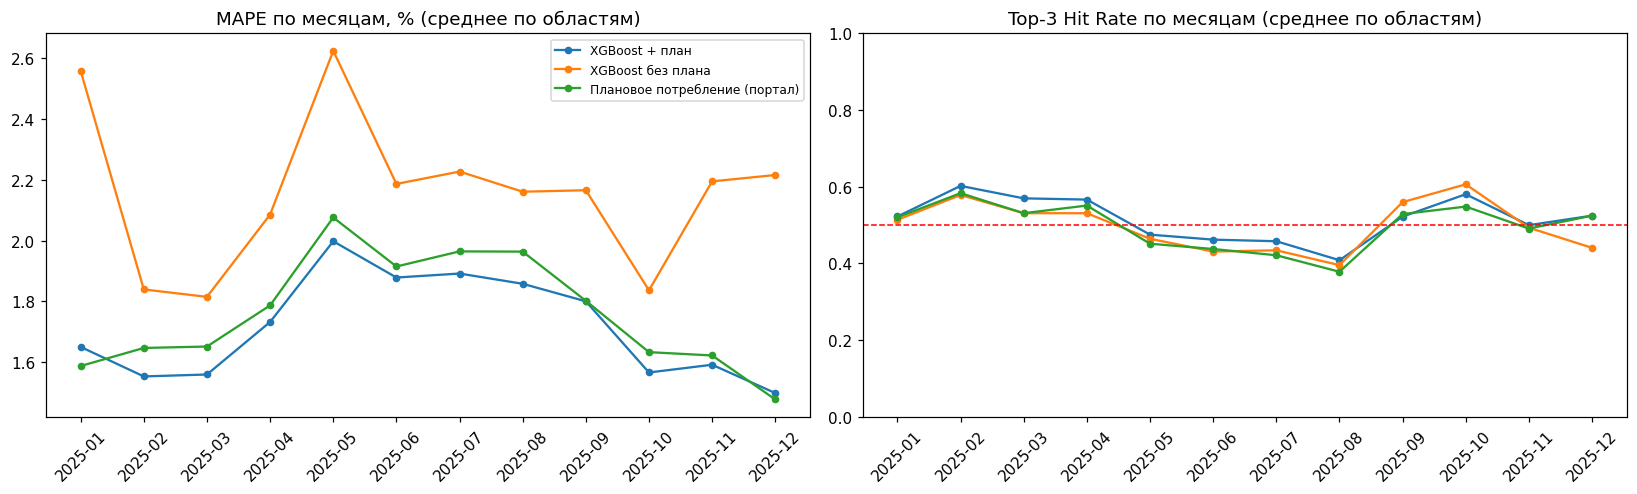

In [34]:
months = test_days.to_period("M")
mon_mape, mon_top3 = {}, {}
for v in [V_PLAN, V_NOPLAN, B_PLAN]:
    tmp_m, tmp_t = {}, {}
    for n in Y:
        e = np.where(MT[n], np.abs(PRED[n][v] - YT[n]) / YT[n], np.nan)
        h = topn_hits(YT[n], PRED[n][v], MT[n], 3)
        tmp_m[n] = pd.Series(np.nanmean(e, axis=1)*100, index=months).groupby(level=0).mean()
        tmp_t[n] = pd.Series(h, index=months).groupby(level=0).mean()
    mon_mape[v] = pd.DataFrame(tmp_m).mean(axis=1)
    mon_top3[v] = pd.DataFrame(tmp_t).mean(axis=1)

fig, ax = plt.subplots(1, 2, figsize=(15, 4.6))
for v in mon_mape:
    ax[0].plot(mon_mape[v].index.astype(str), mon_mape[v], marker="o", ms=4, label=v)
    ax[1].plot(mon_top3[v].index.astype(str), mon_top3[v], marker="o", ms=4, label=v)
ax[0].set_title("MAPE по месяцам, % (среднее по областям)")
ax[1].set_title("Top-3 Hit Rate по месяцам (среднее по областям)")
ax[1].axhline(0.5, ls="--", c="red", lw=1); ax[1].set_ylim(0, 1)
for a in ax: a.tick_params(axis="x", rotation=45)
ax[0].legend(fontsize=8)
fig.tight_layout(); fig.savefig("figures/01_monthly.png", dpi=200, bbox_inches="tight"); plt.show()

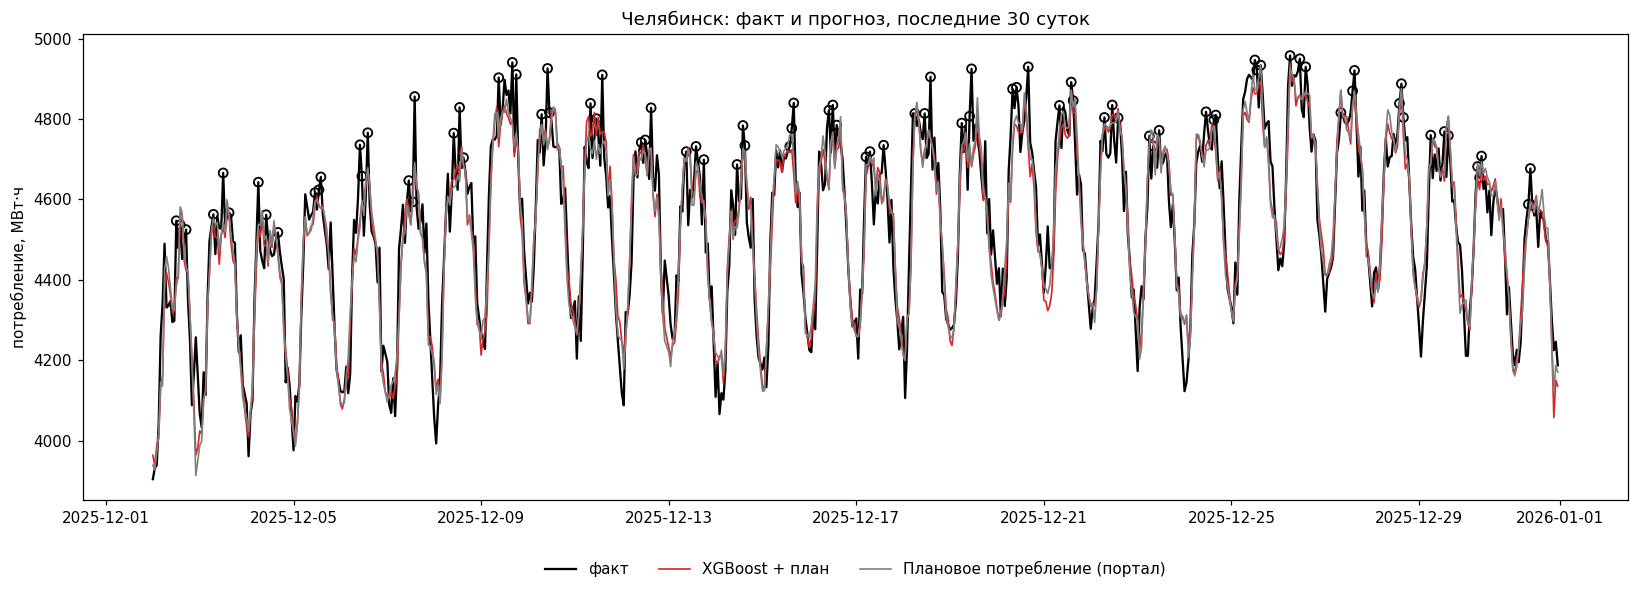

In [35]:
FOCUS = "Челябинск"
W = 30
Yf, Mf = YT[FOCUS][-W:], MT[FOCUS][-W:]
days_w = test_days[-W:]
idx_w = pd.date_range(days_w[0], periods=W*24, freq="h")
t3 = np.argsort(np.where(Mf, Yf, -np.inf), axis=1)[:, -3:]

fig, ax = plt.subplots(figsize=(15, 5.5))
ax.plot(idx_w, Yf.ravel(), "k", lw=1.5, label="факт")
for v, c in [(V_PLAN, "C3"), (B_PLAN, "gray")]:
    ax.plot(idx_w, PRED[FOCUS][v][-W:].ravel(), c=c, lw=1.1, label=v)
for d in range(W):
    ax.scatter(idx_w[d*24 + t3[d]], Yf[d, t3[d]], s=34, facecolors="none", edgecolors="k", lw=1.2)
ax.set_ylabel("потребление, МВт·ч")
ax.set_title(f"{FOCUS}: факт и прогноз, последние {W} суток")
ax.legend(loc="upper center", ncol=3, bbox_to_anchor=(0.5, -0.1), frameon=False)
fig.tight_layout(); fig.savefig("figures/02_fact_vs_forecast.png", dpi=200, bbox_inches="tight"); plt.show()

## 6. Сохранение результатов

Прогнозы в «длинном» формате по всем областям, метрики в CSV.

In [36]:
long_rows = []
for n in Y:
    long_rows.append(pd.DataFrame({
        "region": n,
        "date": np.repeat(test_days.values, 24),
        "hour": np.tile(np.arange(24), len(test_days)),
        "actual": YT[n].ravel(),
        "actual_valid": MT[n].ravel(),
        "pred_xgb_plan": PRED[n][V_PLAN].ravel(),
        "pred_xgb_noplan": PRED[n][V_NOPLAN].ravel(),
        "plan": PRED[n][B_PLAN].ravel(),
    }))
long = pd.concat(long_rows, ignore_index=True)
long.to_csv("results/forecast_predictions_all_regions.csv", index=False)
res.round(4).to_csv("results/forecast_metrics_all_regions.csv", index=False)
avg.round(4).to_csv("results/forecast_metrics_avg.csv")
print("Сохранено: results/forecast_predictions_all_regions.csv, results/forecast_metrics_all_regions.csv, results/forecast_metrics_avg.csv")
print(avg[["MAE", "RMSE", "R2", "MAPE", "Top1", "Top3", "Top5"]].round(3))

Сохранено: results/forecast_predictions_all_regions.csv, results/forecast_metrics_all_regions.csv, results/forecast_metrics_avg.csv
                                  MAE     RMSE     R2   MAPE   Top1   Top3  \
variant                                                                      
XGBoost + план                 31.518   40.084  0.974  1.716  0.264  0.515   
XGBoost без плана              46.177   60.662  0.956  2.161  0.268  0.498   
Плановое потребление (портал)  31.839   40.494  0.973  1.762  0.260  0.497   
Как неделю назад               84.107  110.157  0.870  3.608  0.223  0.448   

                                Top5  
variant                               
XGBoost + план                 0.628  
XGBoost без плана              0.614  
Плановое потребление (портал)  0.611  
Как неделю назад               0.569  
